### Per-nucleus calcium transients in hiPSC-vCMs after CARBONITE
#### Lavie Ngo
#### This notebook: Plots the per-nucleus Rhod-2 calcium transients from steps 1-4 of the pipeline: example traces, per-well heatmaps and mean traces, spatial maps, and per-well summaries comparing maintenance vs. Feyen media at 1 and 2 weeks.

#### Experiment info:
- Differentiated vCMs (D0: 08/31/26) were replated on D18 (09/18/26) into two 96-well plates and cultured in maintenance media until D25 (09/25/26). On D25, wells were moved to their assigned media:
    - Wells B02-B09: Maintenance media (control)
    - Wells C02-C09: Feyen maturation media (treatment)
- Plate 1: 1 week in assigned media; CARBONITE (Rhod-2) on 10/02/26, then fixed.
- Plate 2: 2 weeks in assigned media; CARBONITE (Rhod-2) on 10/09/26, then fixed.
- Spontaneous beating (not paced). 1000 frames at 101.73 Hz (9.83 ms/frame, from the TIFF timestamps) = 9.82 s per movie.

#### Pipeline (scripts in this folder, adapted from Alex's `clark-deep-phenotyping/iPSC-CM`):
1. `1-cellpose-nuclei.py`: Cellpose nuclei on DAPI (w1).
2. `2-align-mi.py`: cTnT (w2) aligned to Rhod-2 frame 0 by mutual information.
3. `3-extract-nuclear-transients.py`: nuclei mapped onto the movie with the 7-of-9 core rule; mean Rhod-2 per nucleus per frame.
4. `4-extract-calcium-features.py` + `calcium.py`: dF/F0 = (F - F0)/F0, F0 = 10th percentile; beats detected at 5x each nucleus's own noise.

#### Caveats (read before interpreting):
- **Every DAPI nucleus is included**, cardiomyocyte or not. cTnT-based CM filtering is not done yet, so most nuclei are flat.
- **"beating" (>= 2 detected peaks) is permissive**: flat, noisy nuclei can still pass. Peak dF/F0 distributions are plotted below to help pick a stricter activity threshold.
- Beats are slow (~0.2-0.3 Hz), so each nucleus has only 1-3 transients per movie; beat rate per nucleus is quantised (2 beats = 0.20 Hz, 3 = 0.31 Hz).
- **Excluded:** Plate 1 C07 (alignment failed; see `experiment.yaml`). **Flagged:** Plate 2 C05/C06 (hair/debris in the fixed images, and the C05 fiber is visible in the Rhod-2 movie).
- One well = one replicate; per-well summaries use the median over that well's nuclei.

In [1]:
# Reusable plotting functions
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import calcium

CALCIUM_DIR = Path("../../Calcium")
FIG_DIR = CALCIUM_DIR / "figures"

PLATES = {
    "plate1": "Plate 1: 1 week",
    "plate2": "Plate 2: 2 weeks",
}
CONDITIONS = ["Maintenance media", "Feyen maturation media"]
CONDITION_COLORS = {"Maintenance media": "#4C72B0", "Feyen maturation media": "#DD8452"}
FLAGGED_WELLS = {("plate2", "C05"): "debris", ("plate2", "C06"): "debris"}

# dF/F0 settings: calcium.py defaults (Alex's), so plots match the pipeline
DFF_SETTINGS = {"f0_pct": calcium.F0_PCT, "smooth": calcium.SMOOTH, "trim": calcium.TRIM}

# Per-well summary metrics: column -> (axis label, scale)
METRICS = {
    "pct_beating": ("Nuclei counted (%)", 1),
    "beat_rate": ("Beat rate (Hz)", 1),
    "amplitude": ("Amplitude (dF/F0)", 1),
    "peak_dff": ("Peak dF/F0", 1),
    "time_to_peak": ("Time to peak (ms)", 1000),
    "duration_50": ("Duration at 50% (ms)", 1000),
    "duration_90": ("Duration at 90% (ms)", 1000),
    "tau_decay": ("Decay tau (ms)", 1000),
}


def load_features(plates=PLATES):
    """One row per nucleus, both plates (step-4 output)."""
    frames = [pd.read_csv(CALCIUM_DIR / plate / "calcium_features.csv") for plate in plates]
    return pd.concat(frames, ignore_index=True)


def load_traces(plate, well):
    """Raw traces for one well -> (ObjectNumber array, F matrix [nuclei x frames], dt)."""
    tr = pd.read_parquet(CALCIUM_DIR / plate / "nuclear_traces.parquet", filters=[("Well", "==", well)])
    if tr.empty:
        raise ValueError(f"No traces for {plate} {well} (excluded or not extracted).")
    return tr.ObjectNumber.to_numpy(), np.stack(tr.CalciumTrace.to_numpy()), float(tr.FrameInterval_s.iloc[0])


def dff_matrix(F, settings=DFF_SETTINGS):
    """dF/F0 for every row of F with calcium.dff(), so plots use the pipeline's exact maths."""
    return np.stack([calcium.dff(row, settings["f0_pct"], settings["smooth"], settings["trim"]) for row in F])


def time_axis(n_frames, dt, trim=DFF_SETTINGS["trim"]):
    return (np.arange(n_frames) + trim) * dt


def _save(fig, name):
    if name is None:
        return
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Exported: {path}")


def well_label(plate, well):
    flag = FLAGGED_WELLS.get((plate, well))
    return f"{well} ({flag})" if flag else well


def plot_example_traces(plate, wells, features, n_top=3, n_random=5, seed=0, export_name=None):
    """Per well: the n_top highest-peak nuclei (red) and n_random random beating nuclei (grey),
    with the mean of all nuclei (black). Rows = wells."""
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(wells), 1, figsize=(10, 2.2 * len(wells)), sharex=True, squeeze=False)
    for ax, well in zip(axes[:, 0], wells):
        objects, F, dt = load_traces(plate, well)
        d = dff_matrix(F)
        t = time_axis(d.shape[1], dt)
        f = features.query("Plate == @plate and Well == @well").set_index("ObjectNumber").loc[objects]
        beating = np.flatnonzero(f.beating.to_numpy())
        top = np.argsort(f.peak_dff.to_numpy())[-n_top:]
        rand = rng.choice(beating, size=min(n_random, beating.size), replace=False)
        for i in rand:
            ax.plot(t, d[i], color="0.6", lw=0.6)
        for i in top:
            ax.plot(t, d[i], color="C3", lw=0.8)
        ax.plot(t, d.mean(axis=0), color="k", lw=1.5)
        condition = f.Condition.iloc[0]
        ax.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {condition} | {len(objects)} nuclei", fontsize=9)
        ax.set_ylabel("dF/F0")
    axes[-1, 0].set_xlabel("Time (s)")
    fig.suptitle(f"red = {n_top} highest-peak nuclei, grey = {n_random} random 'beating' nuclei, black = mean of all nuclei",
                 fontsize=9)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def plot_trace_heatmap(plate, well, features, n_show=300, vmax=0.5, export_name=None):
    """dF/F0 heatmap of the n_show highest-peak nuclei (top row = highest), with the well mean below."""
    objects, F, dt = load_traces(plate, well)
    f = features.query("Plate == @plate and Well == @well").set_index("ObjectNumber").loc[objects]
    order = np.argsort(f.peak_dff.to_numpy())[::-1][:n_show]
    d = dff_matrix(F[order])
    t = time_axis(d.shape[1], dt)
    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
    im = ax0.imshow(d, aspect="auto", cmap="magma", vmin=0, vmax=vmax, extent=(t[0], t[-1], len(order), 0),
                    interpolation="nearest")
    ax0.set_ylabel(f"Nuclei (top {len(order)} of {len(objects)} by peak)")
    ax0.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {f.Condition.iloc[0]}", fontsize=10)
    fig.colorbar(im, ax=[ax0, ax1], label="dF/F0", shrink=0.8)
    ax1.plot(t, dff_matrix(F).mean(axis=0), color="k", lw=1)
    ax1.set_ylabel("mean, all")
    ax1.set_xlabel("Time (s)")
    _save(fig, export_name)
    plt.show()
    return fig


def plot_plate_mean_traces(plate, features, top_frac=0.1, export_name=None):
    """Plate layout (rows = conditions, columns = wells): mean dF/F0 of all nuclei (black) and of the
    top `top_frac` of nuclei by peak dF/F0 (red)."""
    wells = sorted(features.query("Plate == @plate").Well.unique())
    rows = {"B": 0, "C": 1}
    columns = sorted({int(w[1:]) for w in wells})
    fig, axes = plt.subplots(2, len(columns), figsize=(2.2 * len(columns), 4.4), sharex=True, sharey=True, squeeze=False)
    for ax in axes.ravel():
        ax.set_axis_off()
    for well in wells:
        ax = axes[rows[well[0]], columns.index(int(well[1:]))]
        ax.set_axis_on()
        objects, F, dt = load_traces(plate, well)
        d = dff_matrix(F)
        t = time_axis(d.shape[1], dt)
        peak = d.max(axis=1)
        top = peak >= np.quantile(peak, 1 - top_frac)
        ax.plot(t, d[top].mean(axis=0), color="C3", lw=0.8)
        ax.plot(t, d.mean(axis=0), color="k", lw=0.8)
        ax.set_title(well_label(plate, well), fontsize=8)
    for condition_row, condition in enumerate(CONDITIONS):
        axes[condition_row, 0].set_ylabel(f"{condition}\ndF/F0", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Time (s)", fontsize=8)
    fig.suptitle(f"{PLATES[plate]}: mean dF/F0, all nuclei (black) and top {top_frac:.0%} by peak (red)", fontsize=10)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def plot_spatial_map(plate, well, features, metric="peak_dff", vmax=0.5, export_name=None):
    """Nuclei at their calcium-movie position, coloured by a per-nucleus metric."""
    f = features.query("Plate == @plate and Well == @well")
    fig, ax = plt.subplots(figsize=(6, 6))
    sc = ax.scatter(f.live_x, f.live_y, c=f[metric], s=4, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_xlim(0, 682)
    ax.set_ylim(682, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {f.Condition.iloc[0]}", fontsize=10)
    fig.colorbar(sc, ax=ax, label=metric, shrink=0.8)
    _save(fig, export_name)
    plt.show()
    return fig


def plot_peak_distributions(features, export_name=None):
    """Peak dF/F0 per nucleus, by plate and condition (log x). Helps choose an activity threshold."""
    bins = np.logspace(-2, 1, 80)
    fig, axes = plt.subplots(1, len(PLATES), figsize=(5 * len(PLATES), 3.5), sharey=True)
    for ax, (plate, plate_name) in zip(np.atleast_1d(axes), PLATES.items()):
        for condition in CONDITIONS:
            values = features.query("Plate == @plate and Condition == @condition").peak_dff
            ax.hist(values.clip(lower=bins[0]), bins=bins, histtype="step", lw=1.5, density=True,
                    color=CONDITION_COLORS[condition], label=f"{condition} (n={len(values)})")
        ax.set_xscale("log")
        ax.set_xlabel("Peak dF/F0 per nucleus")
        ax.set_title(plate_name)
        ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Density")
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def summarize_wells(features, min_peak_dff=None):
    """One row per well. pct_beating uses all nuclei; the other metrics are medians over the
    well's counted nuclei: beating, and optionally also peak_dff >= min_peak_dff."""
    rows = []
    for (plate, well, condition), f in features.groupby(["Plate", "Well", "Condition"]):
        active = f[f.beating]
        if min_peak_dff is not None:
            active = active[active.peak_dff >= min_peak_dff]
        row = {"Plate": plate, "Well": well, "Condition": condition, "n_nuclei": len(f),
               "n_active": len(active), "pct_beating": 100 * len(active) / len(f),
               "flagged": FLAGGED_WELLS.get((plate, well), "")}
        for metric in METRICS:
            if metric != "pct_beating":
                row[metric] = active[metric].median()
        rows.append(row)
    return pd.DataFrame(rows)


def plot_well_metrics(summary, metrics=METRICS, title=None, export_name=None):
    """One panel per metric: one point per well, grouped by plate and condition, median bar.
    Flagged wells are hollow."""
    metrics = {m: METRICS[m] for m in metrics}
    ncols = 4
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3 * nrows), squeeze=False)
    rng = np.random.default_rng(0)
    positions = {(plate, condition): i + 3 * p for p, plate in enumerate(PLATES)
                 for i, condition in enumerate(CONDITIONS)}
    for ax, (metric, (label, scale)) in zip(axes.ravel(), metrics.items()):
        for (plate, condition), x in positions.items():
            s = summary.query("Plate == @plate and Condition == @condition")
            y = s[metric] * scale
            jitter = x + rng.uniform(-0.15, 0.15, len(s))
            color = CONDITION_COLORS[condition]
            flagged = s.flagged.astype(bool).to_numpy()
            ax.scatter(jitter[~flagged], y[~flagged], s=22, color=color, zorder=3)
            ax.scatter(jitter[flagged], y[flagged], s=22, facecolor="none", edgecolor=color, zorder=3)
            ax.hlines(np.nanmedian(y), x - 0.3, x + 0.3, color="k", lw=1.5)
        ax.set_xticks([0.5 + 3 * p for p in range(len(PLATES))], list(PLATES.values()), fontsize=8)
        ax.set_title(label, fontsize=9)
    for ax in axes.ravel()[len(metrics):]:
        ax.set_axis_off()
    handles = [plt.Line2D([], [], marker="o", ls="", color=CONDITION_COLORS[c], label=c) for c in CONDITIONS]
    handles.append(plt.Line2D([], [], marker="o", ls="", mfc="none", mec="0.3", label="flagged (debris)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(title or "Per-well medians (one point per well; bar = median of wells)", fontsize=10)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    _save(fig, export_name)
    plt.show()
    return fig

In [2]:
# Improve inline figure quality
%config InlineBackend.figure_format = "retina"
plt.rcParams["figure.dpi"] = 100

In [3]:
# Load per-nucleus features (both plates)
features = load_features()
print(f"{len(features)} nuclei, {features.groupby('Plate').Well.nunique().to_dict()} wells")
features.groupby(["Plate", "Condition"]).agg(
    nuclei=("beating", "size"), pct_beating=("beating", "mean"), median_peak_dff=("peak_dff", "median")
).round(3)

77621 nuclei, {'plate1': 15, 'plate2': 16} wells


nuclei  pct_beating  median_peak_dff
Plate  Condition                                                   
plate1 Feyen maturation media   16970        0.518            0.055
       Maintenance media        17136        0.631            0.071
plate2 Feyen maturation media   22376        0.739            0.147
       Maintenance media        21139        0.765            0.142

#### Example traces
Two wells per condition per plate. Red = the 3 highest-peak nuclei, grey = 5 random "beating" nuclei, black = mean of all nuclei in the well.

Exported: ../../Calcium/figures/plate1_example-traces.png


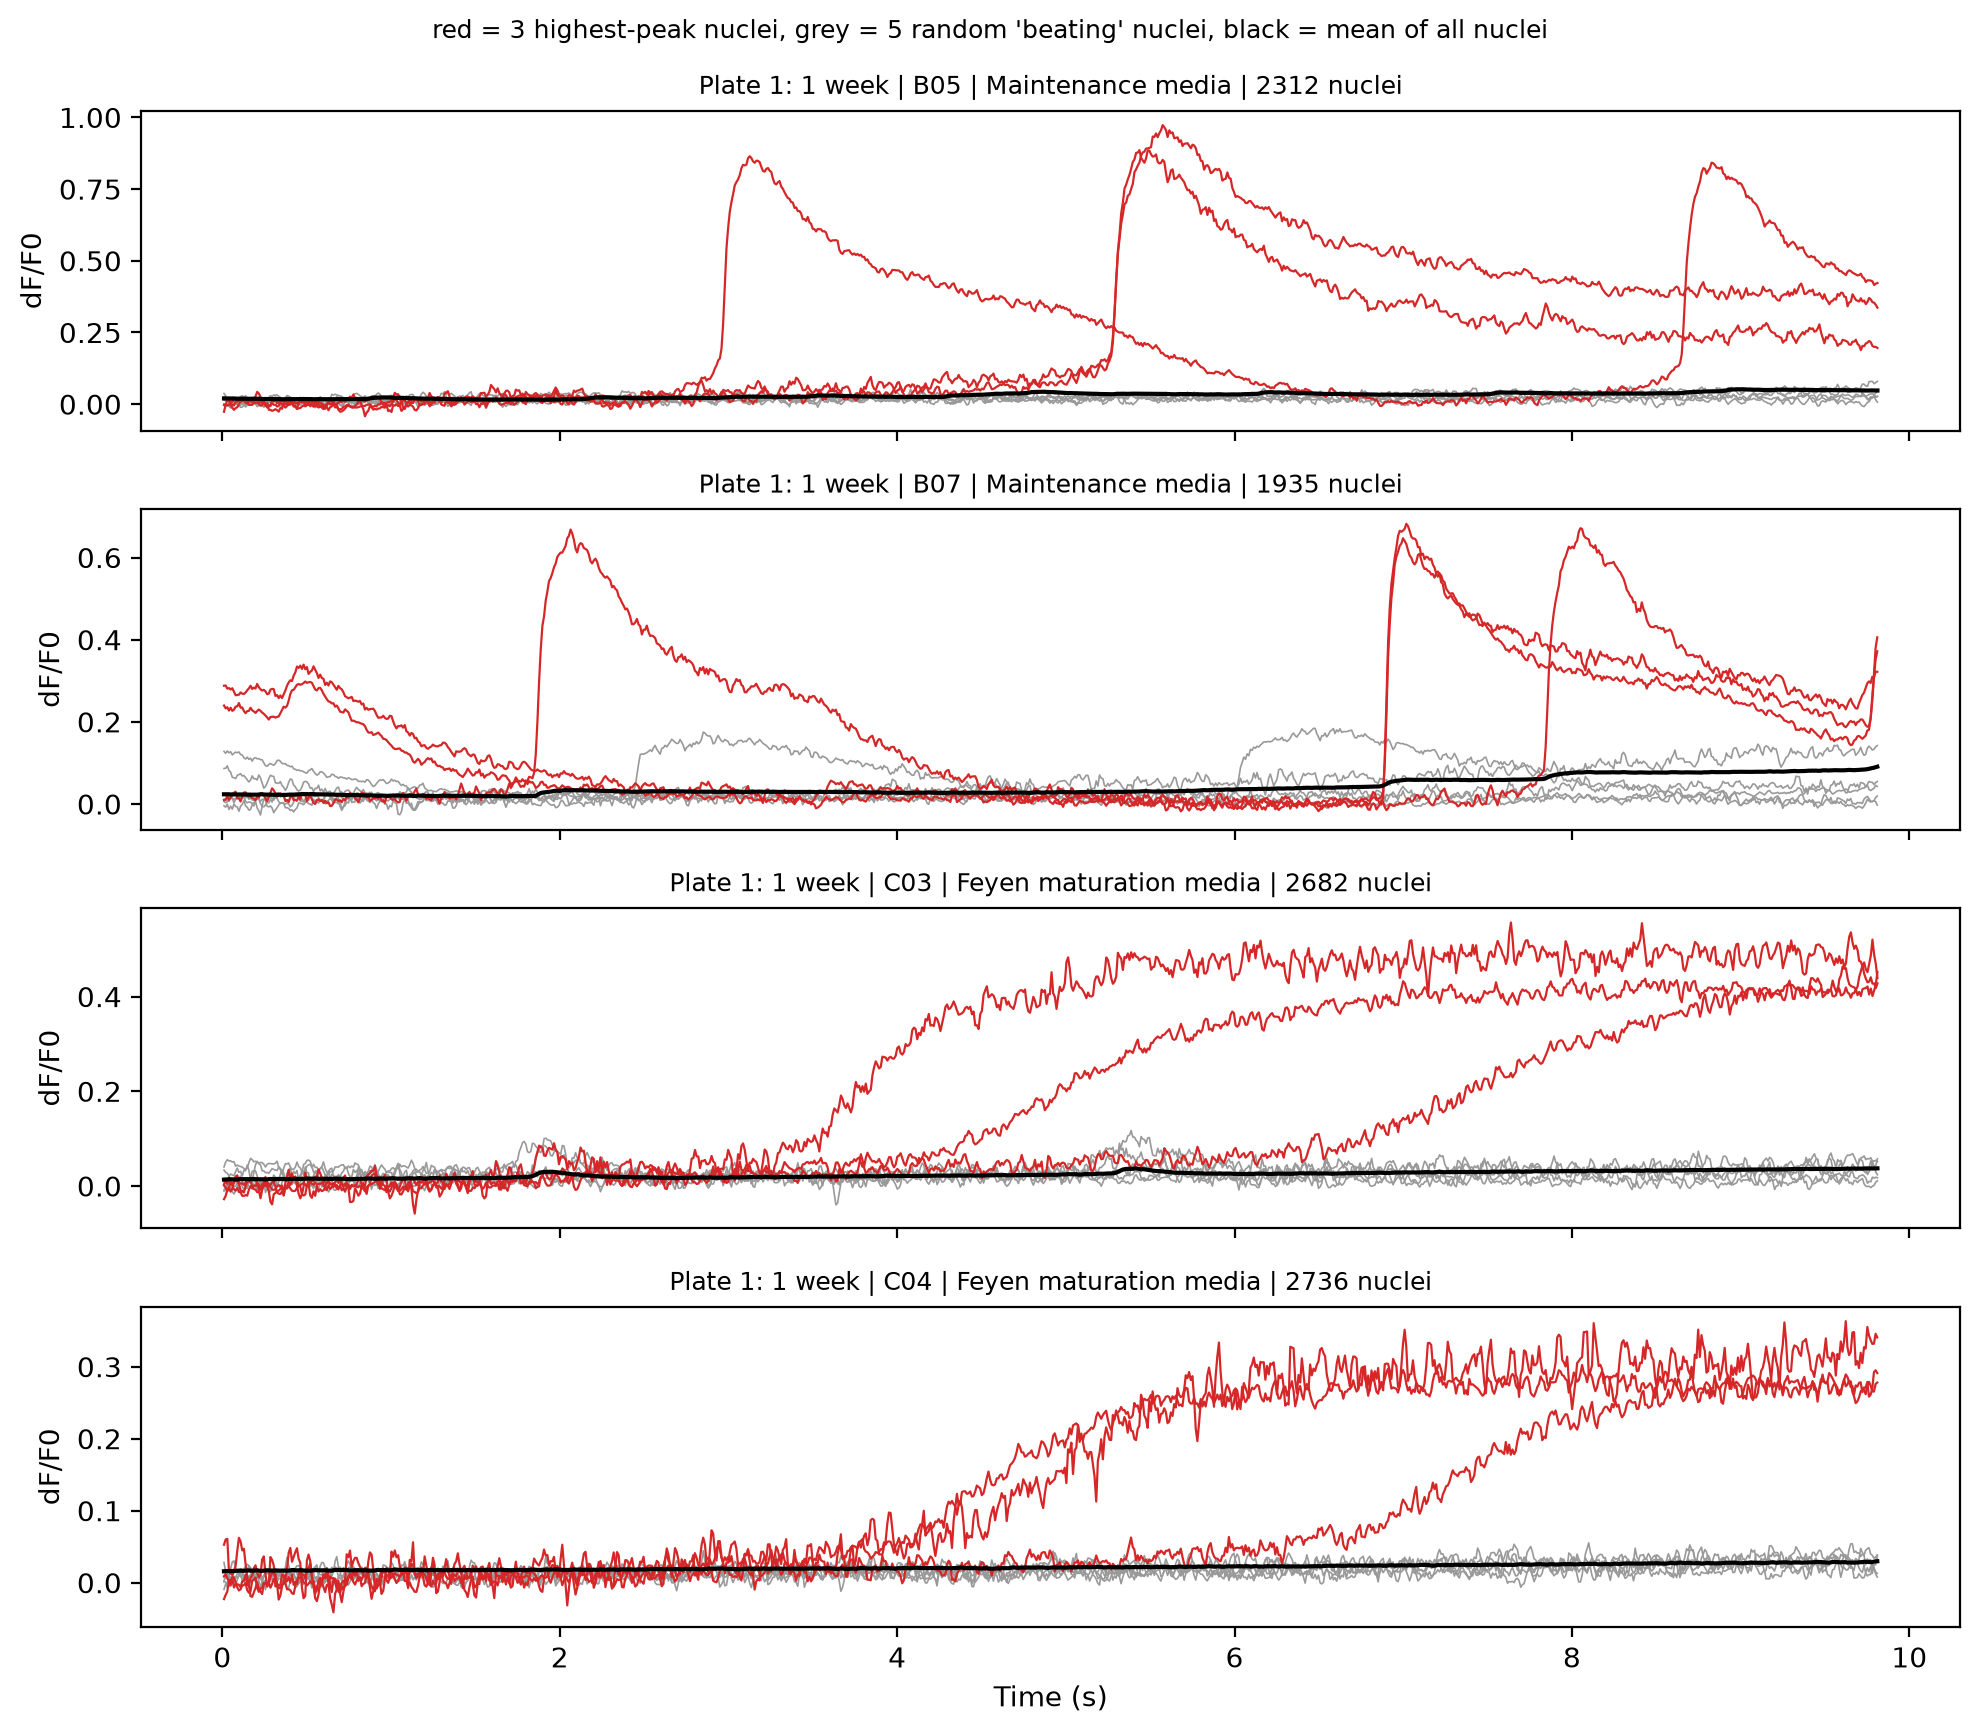

In [4]:
# Plate 1: 1 week in assigned media
plate1_examples = plot_example_traces(
    plate="plate1",
    wells=["B05", "B07", "C03", "C04"],
    features=features,
    n_top=3,
    n_random=5,
    export_name="plate1_example-traces",
)

Exported: ../../Calcium/figures/plate2_example-traces.png


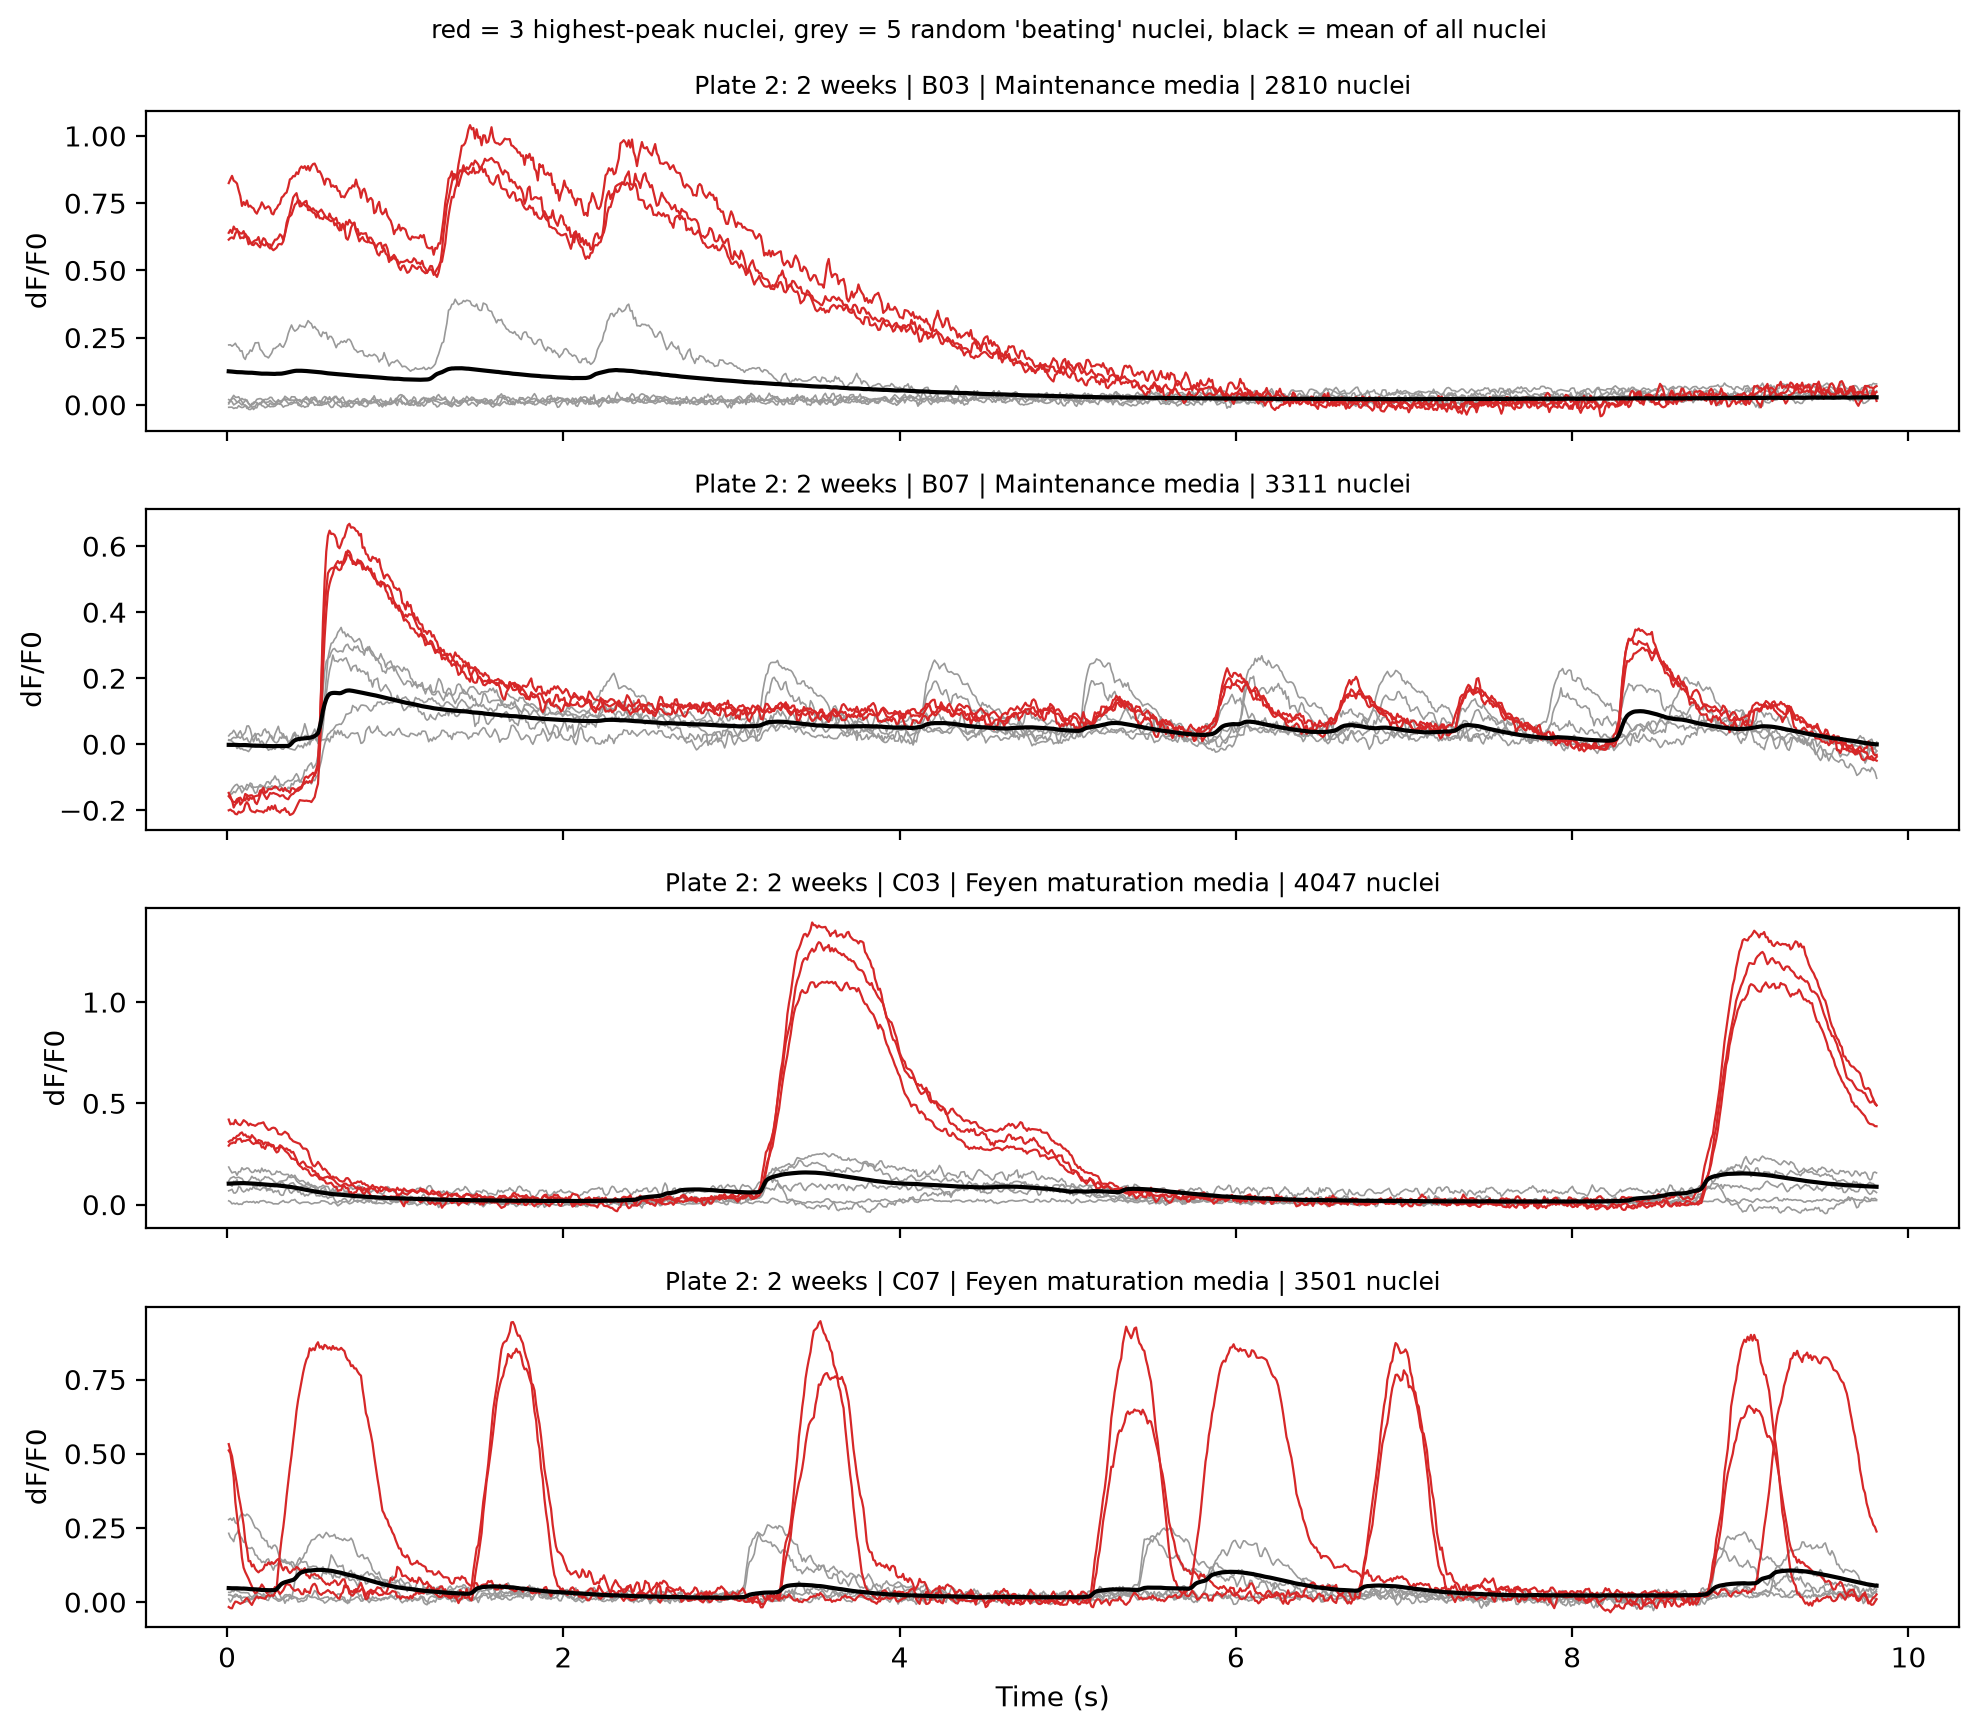

In [5]:
# Plate 2: 2 weeks in assigned media
plate2_examples = plot_example_traces(
    plate="plate2",
    wells=["B03", "B07", "C03", "C07"],
    features=features,
    n_top=3,
    n_random=5,
    export_name="plate2_example-traces",
)

#### Mean traces across each plate
Plate layout: rows = conditions, columns = wells. Black = mean of all nuclei; red = mean of the top 10% of nuclei by peak dF/F0 (a rough stand-in for the active CMs until the cTnT filter exists).

Exported: ../../Calcium/figures/plate1_mean-traces.png


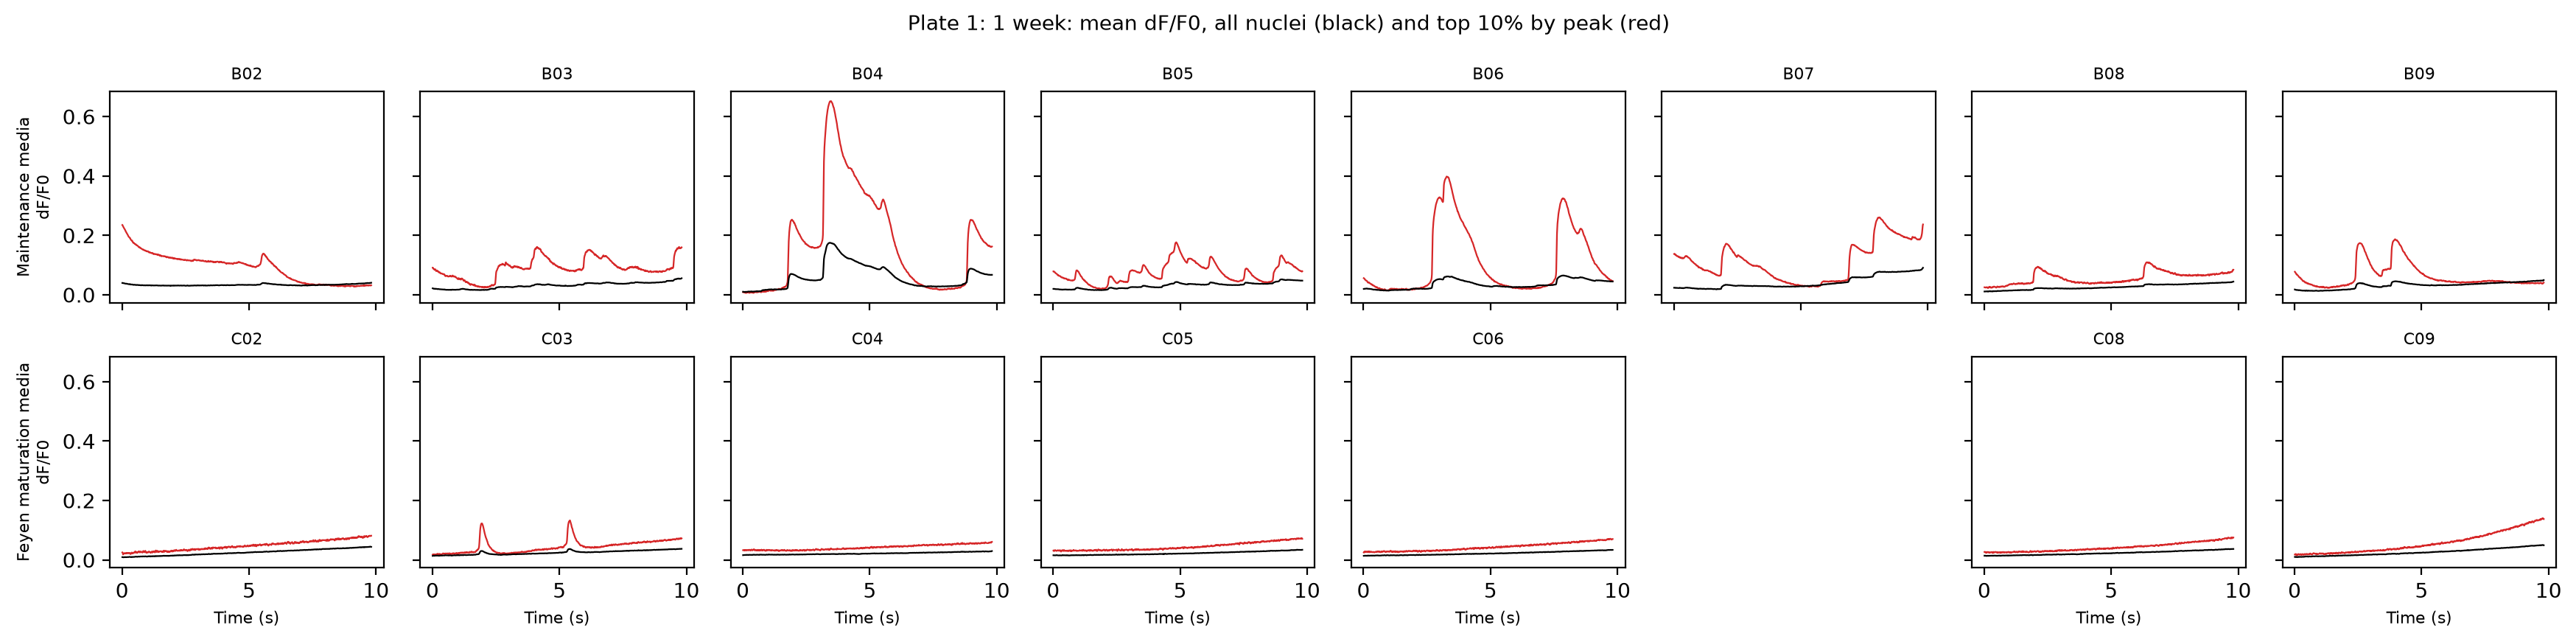

In [6]:
# Plate 1: 1 week in assigned media
plate1_means = plot_plate_mean_traces("plate1", features, top_frac=0.1, export_name="plate1_mean-traces")

Exported: ../../Calcium/figures/plate2_mean-traces.png


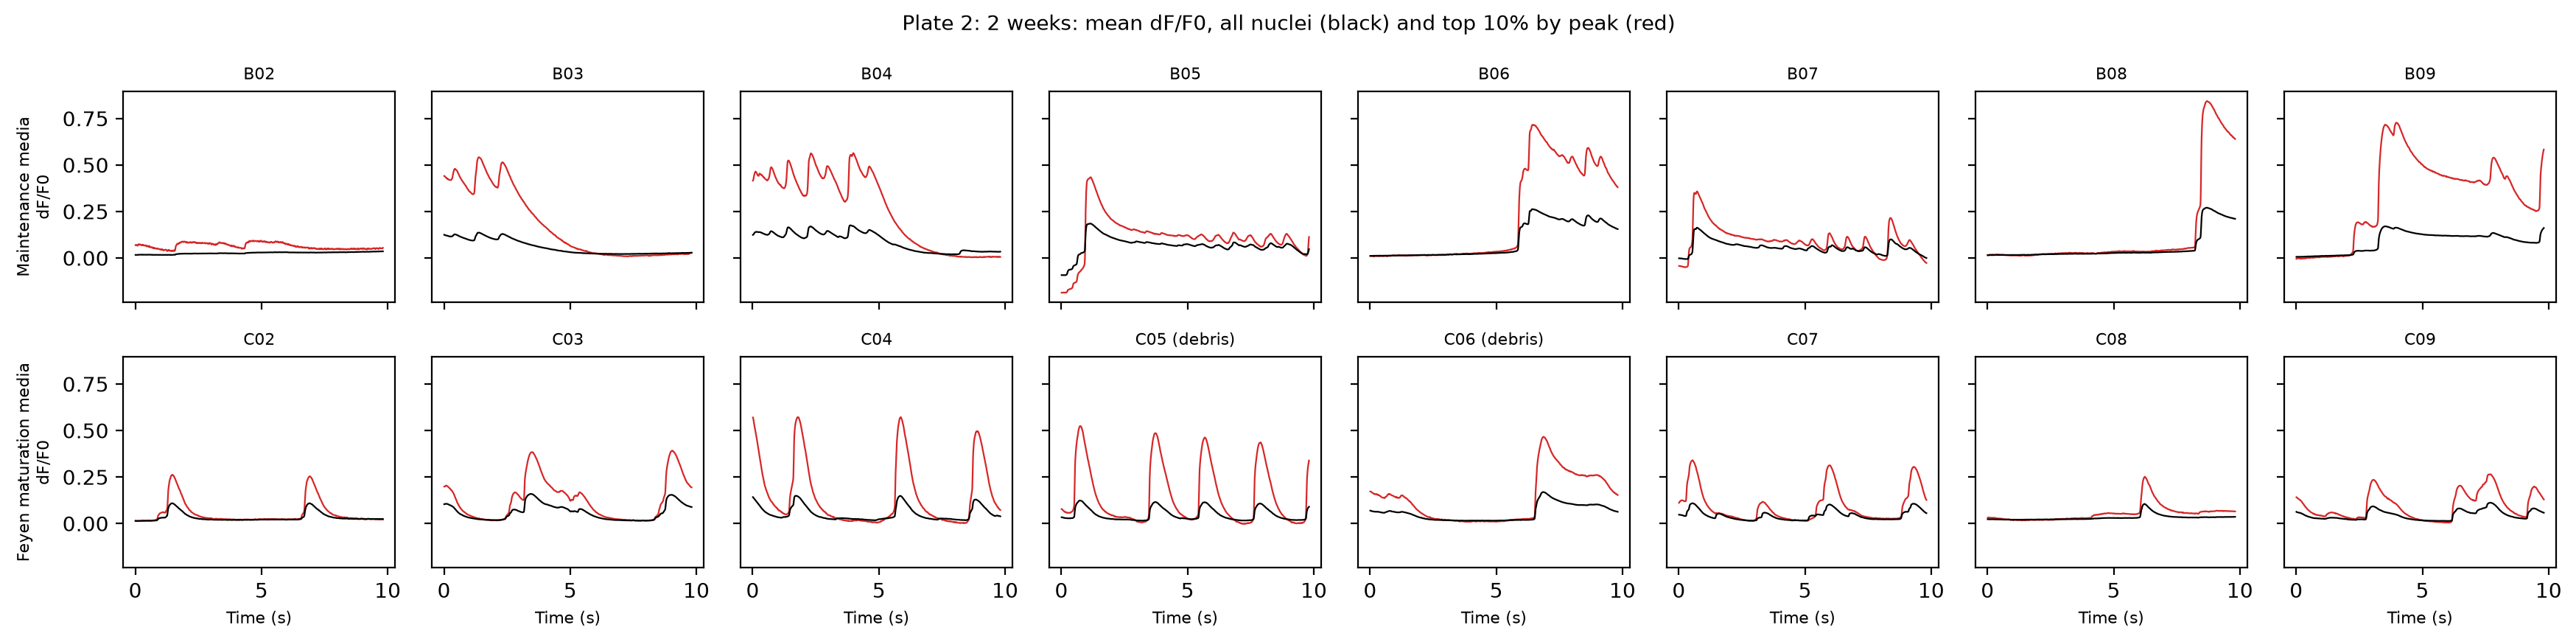

In [7]:
# Plate 2: 2 weeks in assigned media
plate2_means = plot_plate_mean_traces("plate2", features, top_frac=0.1, export_name="plate2_mean-traces")

#### Heatmaps and spatial maps
One well per condition. Heatmap rows are nuclei sorted by peak dF/F0; the spatial map places each nucleus where it sits in the calcium movie (the empty band at the top is outside the fixed image).

Exported: ../../Calcium/figures/plate2_B03_heatmap.png


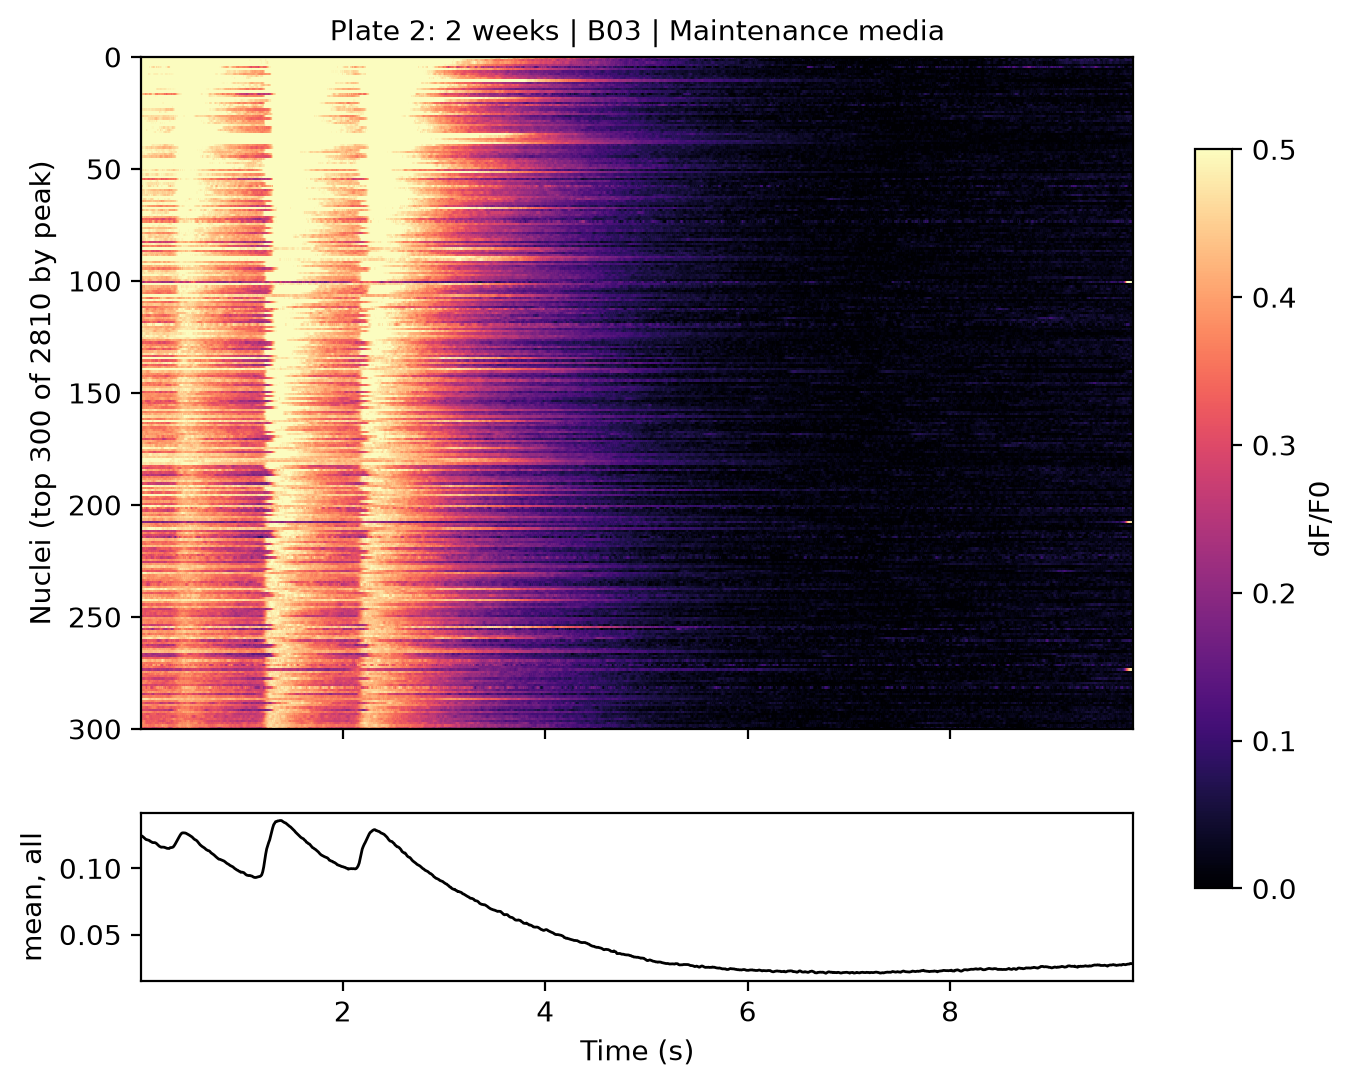

Exported: ../../Calcium/figures/plate2_B03_peak-map.png


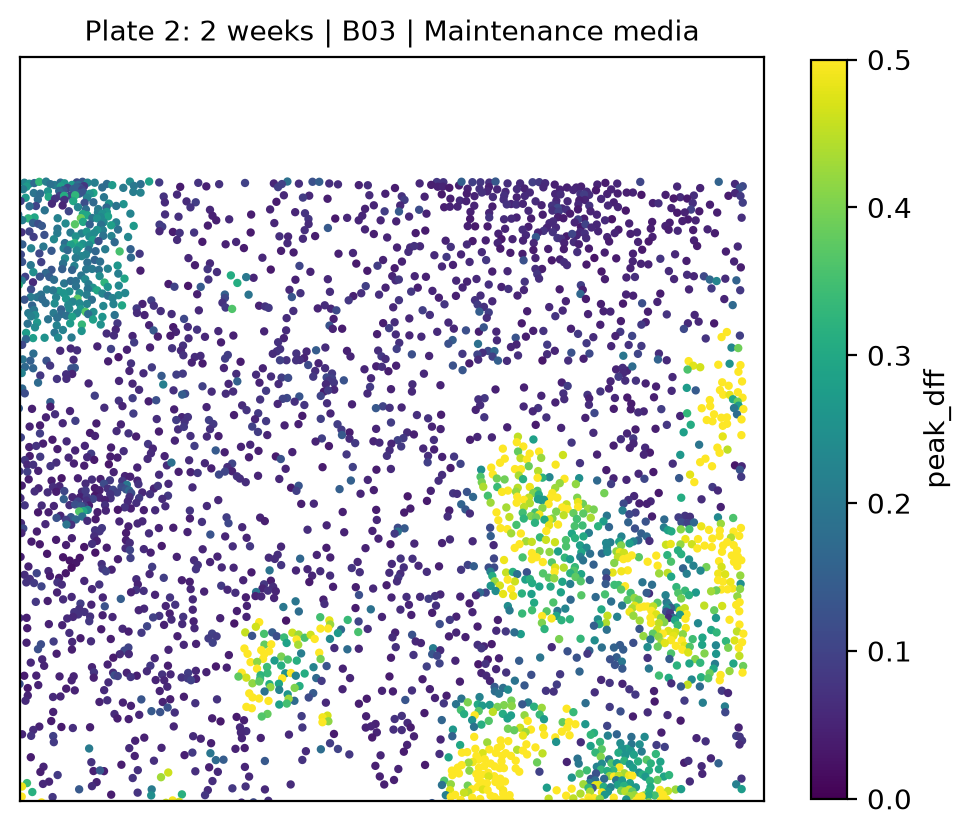

Exported: ../../Calcium/figures/plate2_C03_heatmap.png


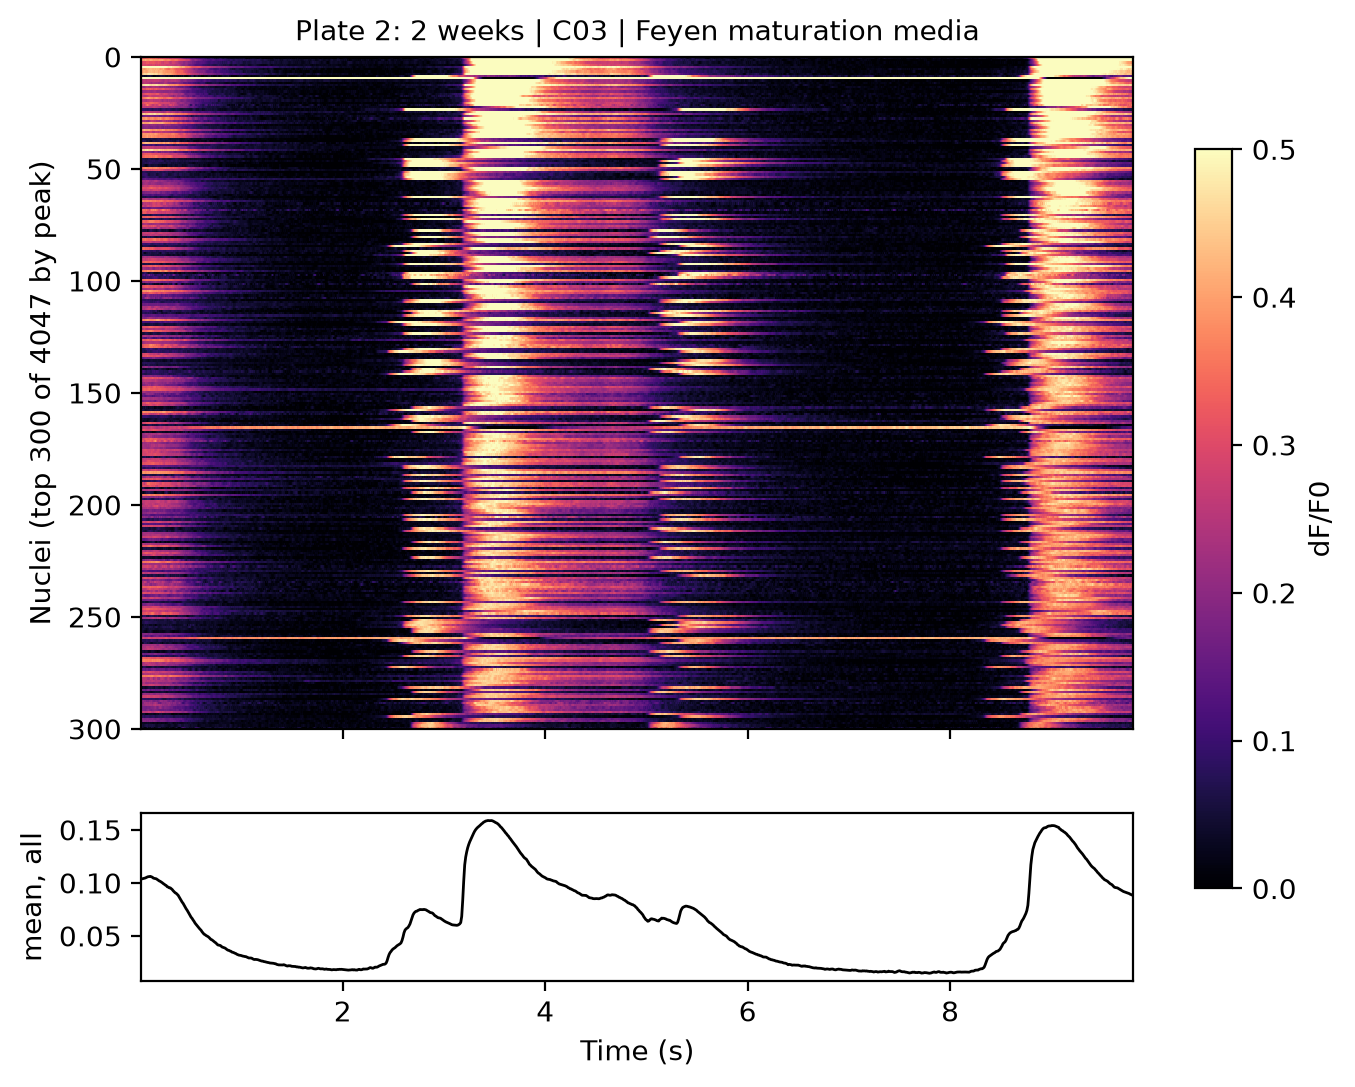

Exported: ../../Calcium/figures/plate2_C03_peak-map.png


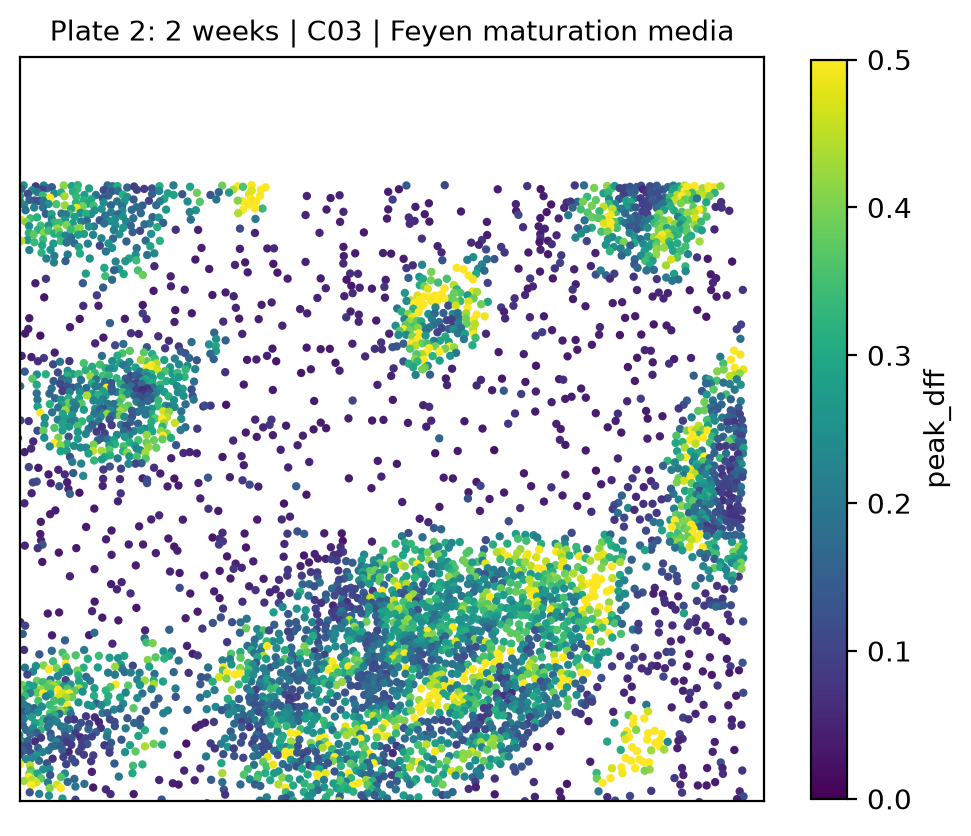

In [8]:
# Plate 2: maintenance (B03) vs. Feyen (C03)
for well in ["B03", "C03"]:
    plot_trace_heatmap("plate2", well, features, n_show=300, vmax=0.5, export_name=f"plate2_{well}_heatmap")
    plot_spatial_map("plate2", well, features, metric="peak_dff", vmax=0.5, export_name=f"plate2_{well}_peak-map")

#### Peak dF/F0 distributions
Most nuclei sit near the noise floor; active CMs form the right-hand tail. Use this to choose `min_peak_dff` below.

Exported: ../../Calcium/figures/peak-dff-distributions.png


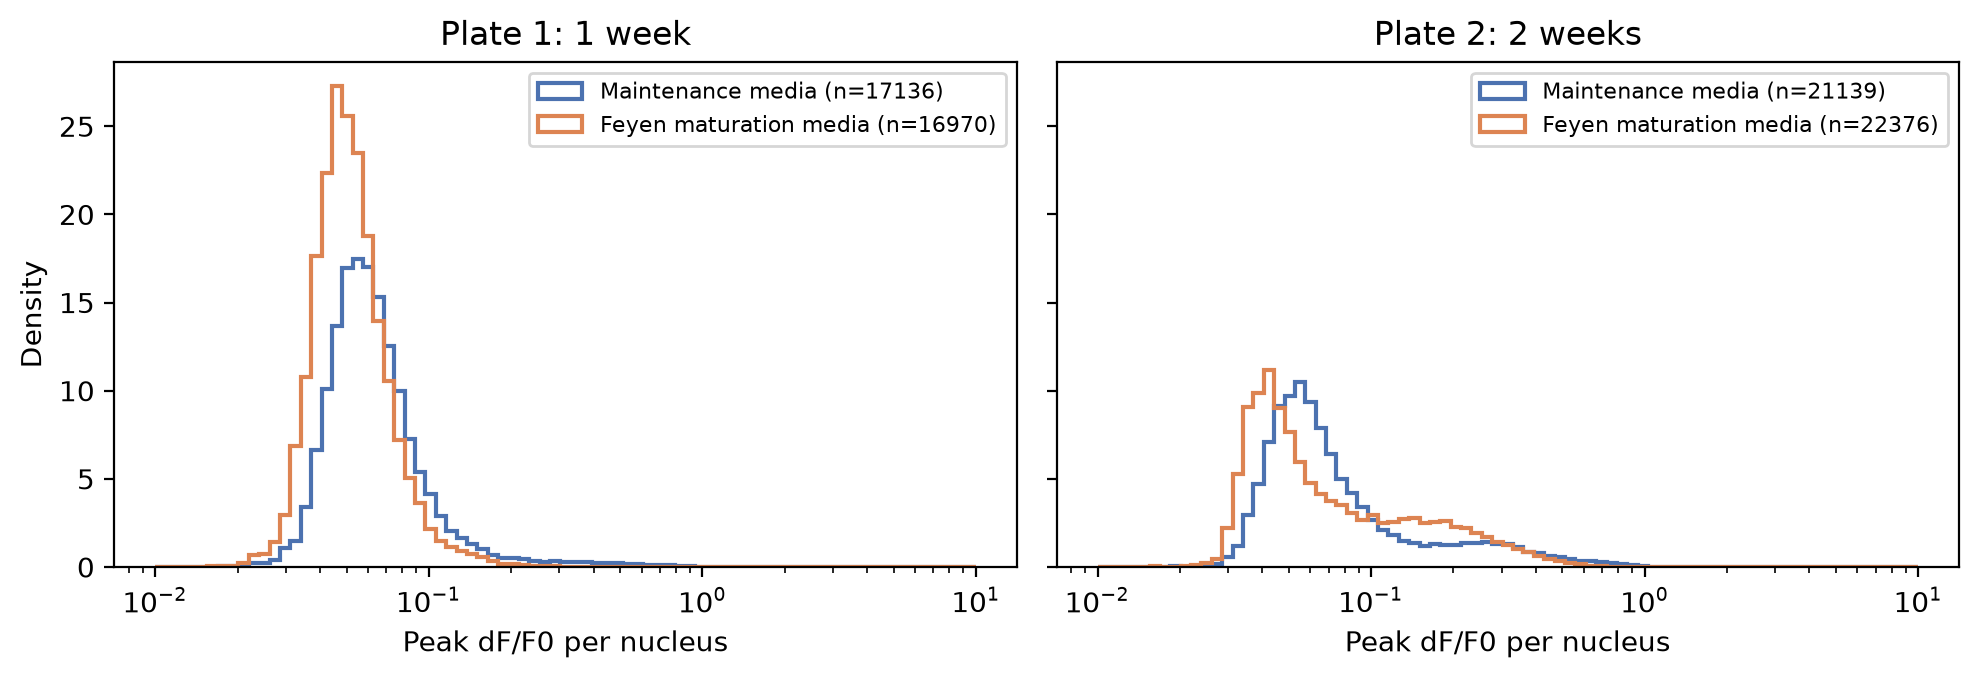

In [9]:
peak_distributions = plot_peak_distributions(features, export_name="peak-dff-distributions")

#### Per-well summaries
Each point is one well (median over its nuclei). Two versions:
1. **All "beating" nuclei** (>= 2 peaks, Alex's default). Dominated by flat non-CM nuclei.
2. **Active nuclei only**: also require peak dF/F0 >= `MIN_PEAK_DFF`. This threshold is a placeholder until the cTnT filter is added.

These are exploratory; no statistics yet (n = 7-8 wells per group).

Exported: ../../Calcium/figures/well-metrics_beating.png


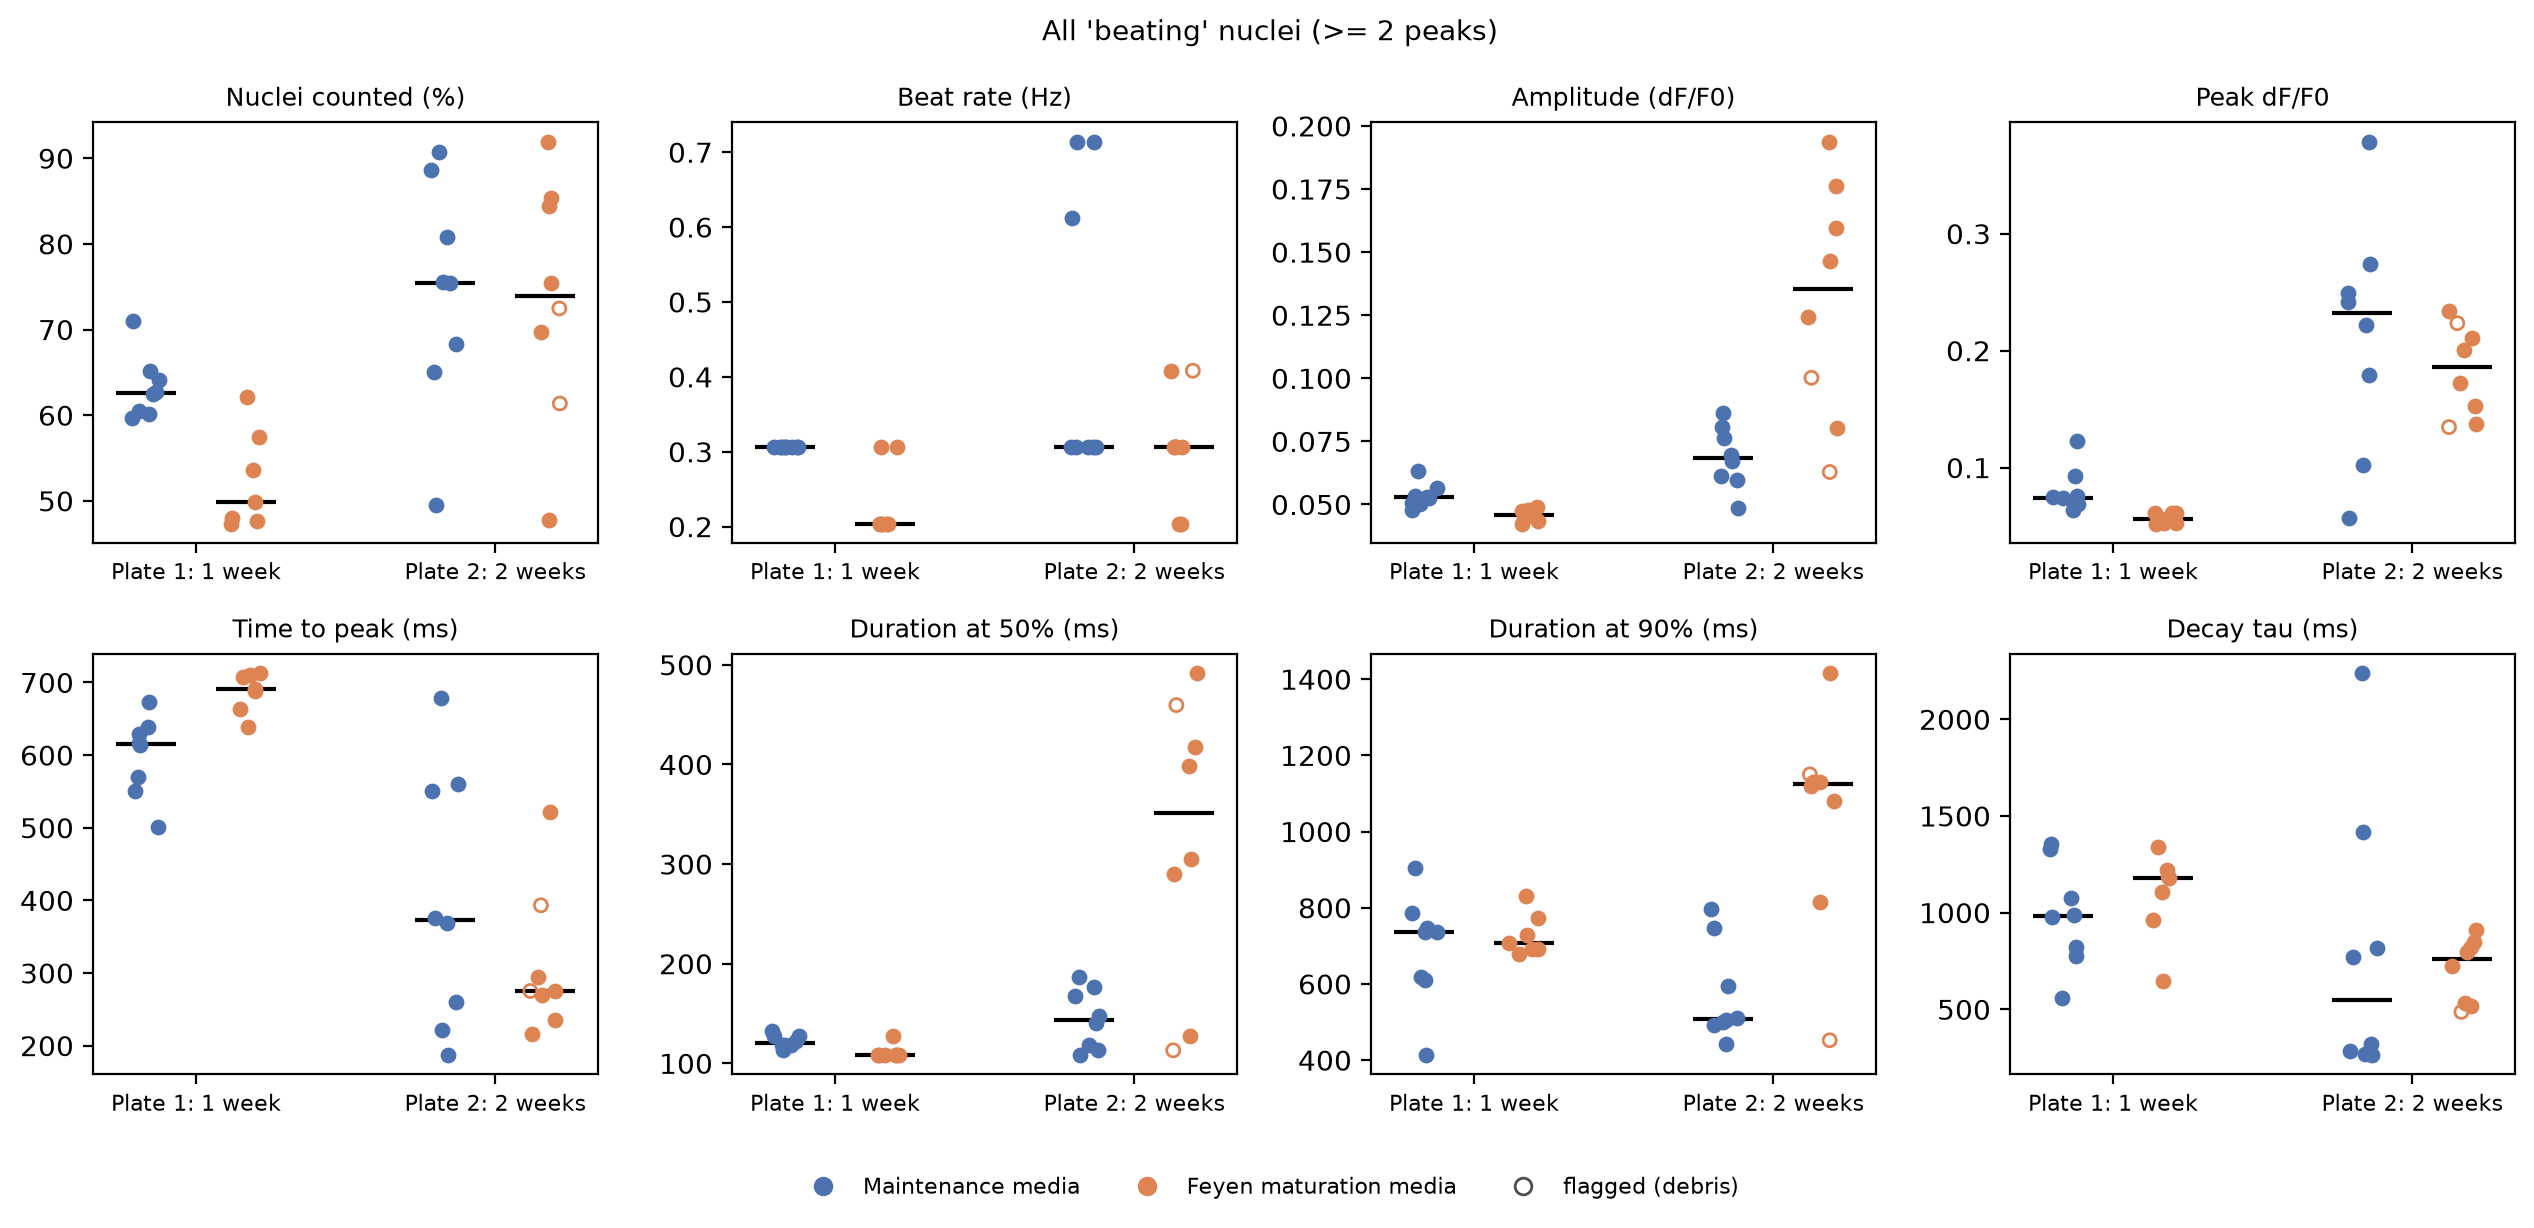

In [10]:
# Version 1: Alex's default "beating" definition
summary_all = summarize_wells(features)
summary_all.to_csv(CALCIUM_DIR / "well_summary_beating.csv", index=False)
well_metrics_all = plot_well_metrics(summary_all, title="All 'beating' nuclei (>= 2 peaks)",
                                     export_name="well-metrics_beating")

Exported: ../../Calcium/figures/well-metrics_active-peak0.2.png


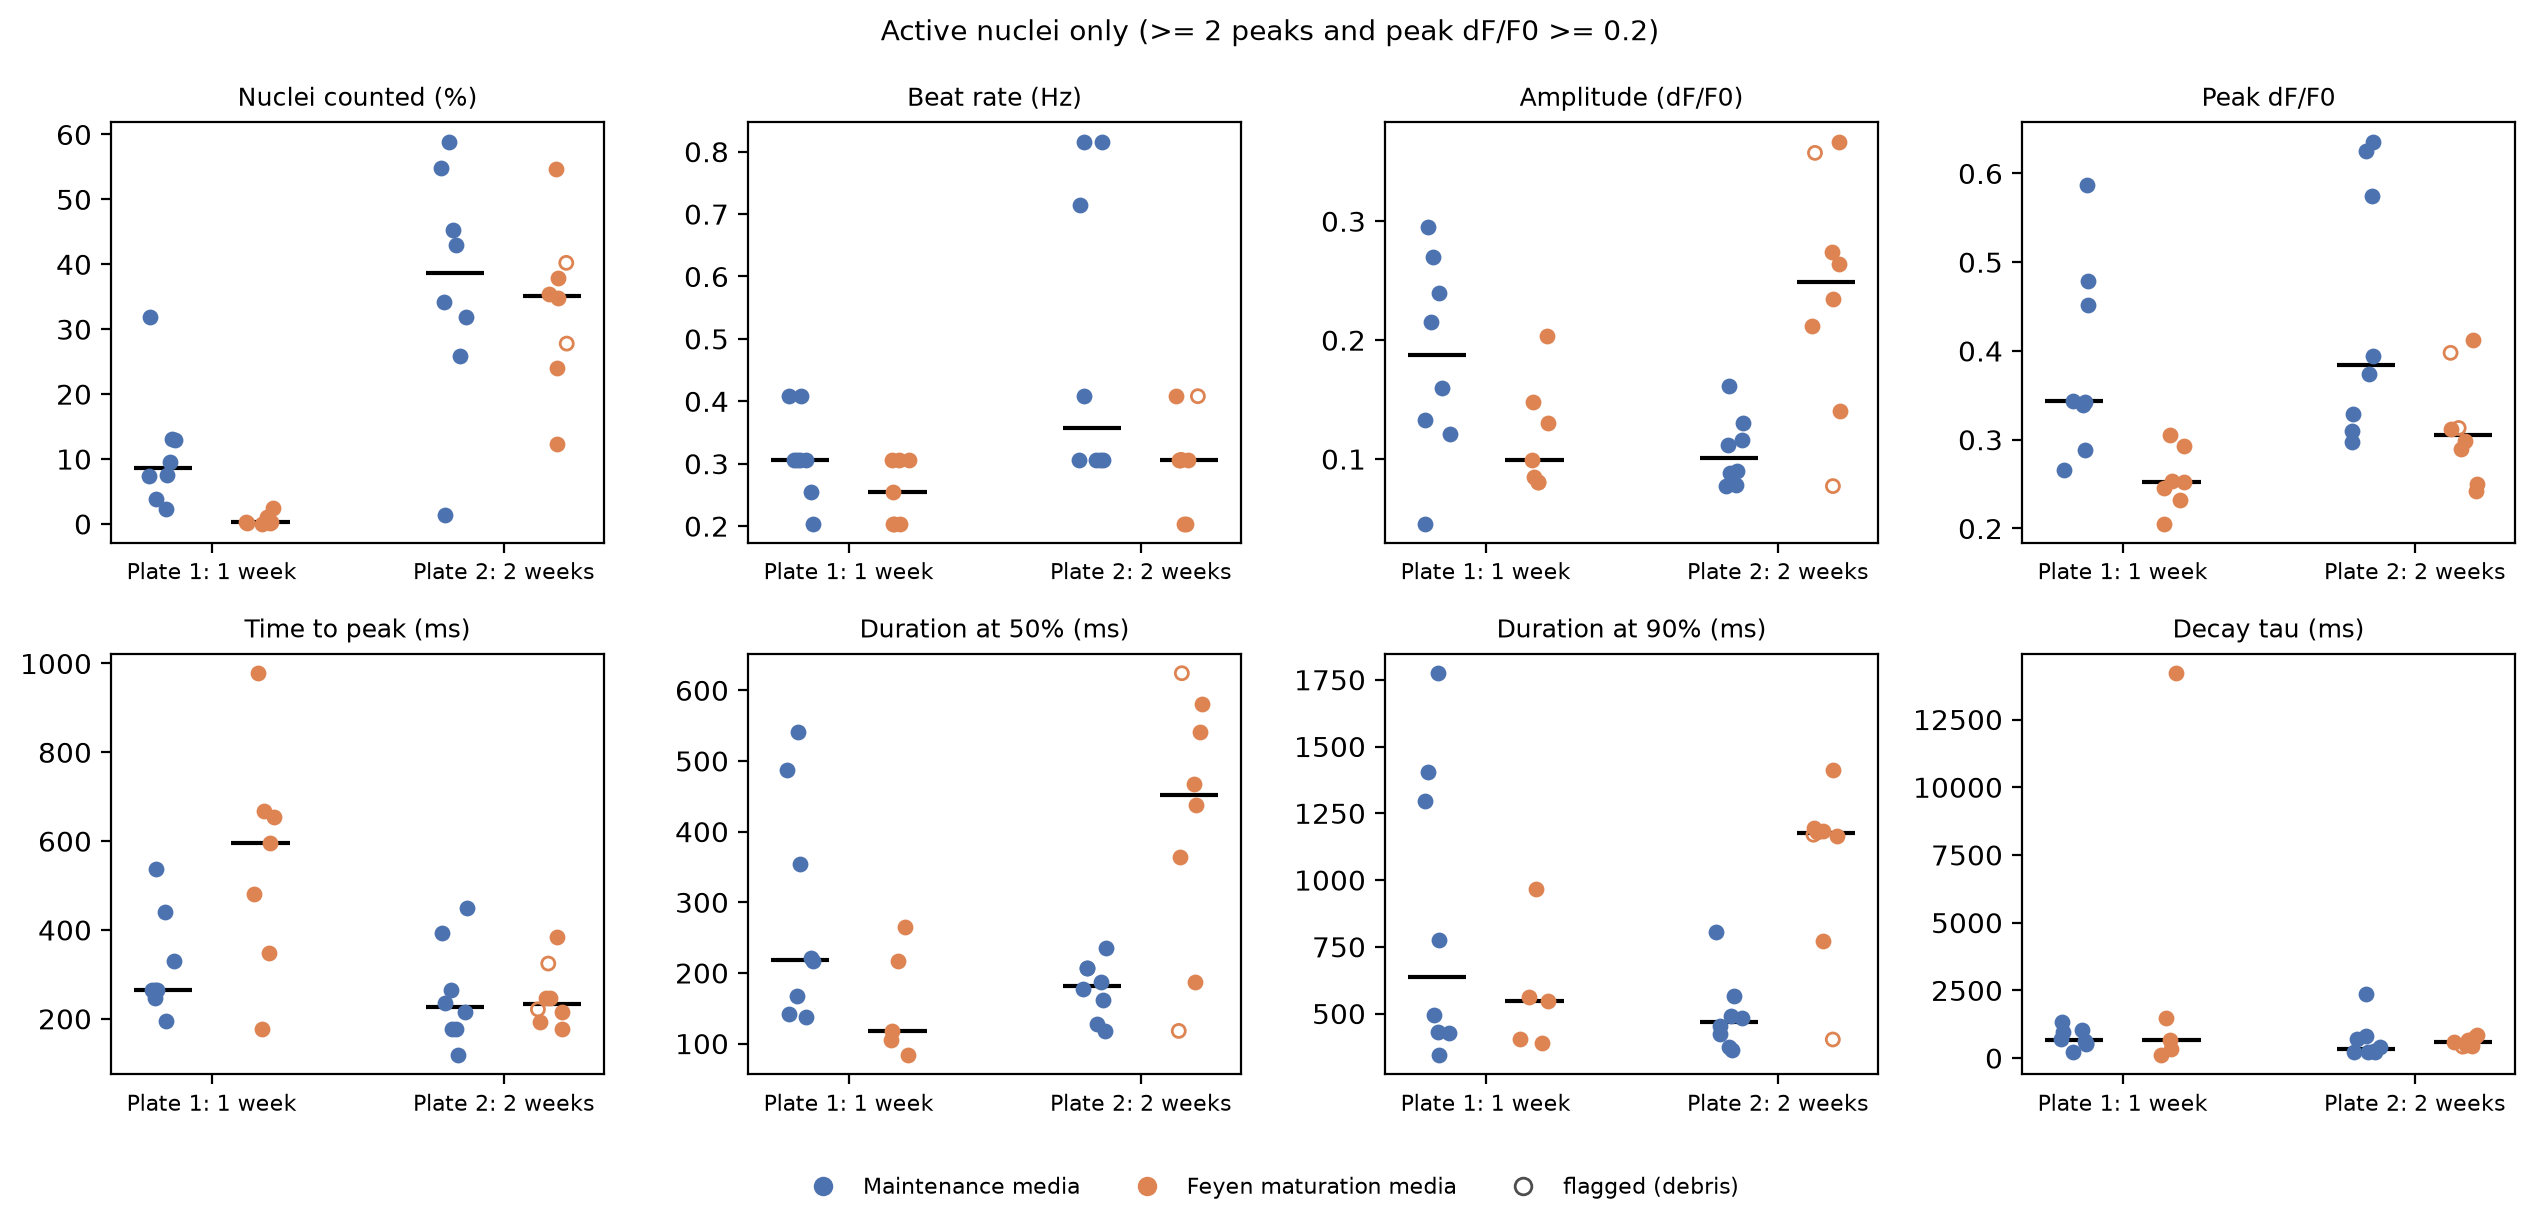

In [11]:
# Version 2: active nuclei only (placeholder threshold)
MIN_PEAK_DFF = 0.2
summary_active = summarize_wells(features, min_peak_dff=MIN_PEAK_DFF)
summary_active.to_csv(CALCIUM_DIR / f"well_summary_active-peak{MIN_PEAK_DFF}.csv", index=False)
well_metrics_active = plot_well_metrics(summary_active, title=f"Active nuclei only (>= 2 peaks and peak dF/F0 >= {MIN_PEAK_DFF})",
                                        export_name=f"well-metrics_active-peak{MIN_PEAK_DFF}")

In [12]:
# Per-well table (active nuclei)
summary_active.round(3)

,Plate,Well,Condition,n_nuclei,n_active,pct_beating,flagged,beat_rate,amplitude,peak_dff,time_to_peak,duration_50,duration_90,tau_decay
0,plate1,B02,Maintenance media,1869,142,7.598,,0.306,0.046,0.289,0.538,0.138,0.496,0.237
1,plate1,B03,Maintenance media,2138,82,3.835,,0.408,0.240,0.451,0.265,0.216,0.428,0.545
2,plate1,B04,Maintenance media,2178,694,31.864,,0.306,0.215,0.587,0.329,0.143,0.344,1.045
3,plate1,B05,Maintenance media,2312,171,7.396,,0.408,0.160,0.266,0.246,0.221,0.777,0.533
4,plate1,B06,Maintenance media,2376,310,13.047,,0.306,0.295,0.479,0.265,0.487,1.406,0.955
5,plate1,B07,Maintenance media,1935,251,12.972,,0.306,0.121,0.343,0.265,0.167,0.433,1.343
6,plate1,B08,Maintenance media,2356,56,2.377,,0.255,0.270,0.339,0.194,0.541,1.774,0.716
7,plate1,B09,Maintenance media,1972,188,9.533,,0.204,0.133,0.344,0.440,0.354,1.298,0.632
8,plate1,C02,Feyen maturation media,1687,1,0.059,,0.204,0.081,0.206,0.349,NaN,NaN,NaN
9,plate1,C03,Feyen maturation media,2682,67,2.498,,0.306,0.203,0.232,0.177,0.265,0.968,0.343
